# DGX Wildlife Signal Processing Notebook

This notebook is a starter workflow for your uploaded NetCDF wildlife dataset on DGX. It focuses on exploratory signal processing:

- verify the GPU environment
- inspect the uploaded files
- load the NetCDF dataset
- filter to two species and distance under 60 m
- split traces into blocks
- plot the raw signal, FFT spectrum, and spectrogram
- save a smaller working subset for later experiments

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, rfftfreq
from netCDF4 import Dataset

workspace_root = Path.cwd()
DATASET_PATH = workspace_root / 'PROJECT' / 'dset_allspec_150_chunks_clean.nc'

print(f'Workspace root: {workspace_root}')
print(f'Expected dataset path: {DATASET_PATH}')

if not DATASET_PATH.exists():
    raise FileNotFoundError('Expected dataset not found at PROJECT/dset_allspec_150_chunks_clean.nc. Update DATASET_PATH to the uploaded file location on DGX.')

print(f'Using dataset: {DATASET_PATH}')

dset = Dataset(DATASET_PATH, 'r')
print(dset)
print('Variables:', list(dset.variables.keys()))
print('Dimensions:', list(dset.dimensions.keys()))
print('Groups:', list(dset.groups.keys()))

Workspace root: /jupyter/aswin.vs
Expected dataset path: /jupyter/aswin.vs/PROJECT/dset_allspec_150_chunks_clean.nc
Using dataset: /jupyter/aswin.vs/PROJECT/dset_allspec_150_chunks_clean.nc
<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): time(2048), traces(70637), comp(3), side(128)
    variables(dimensions): float32 chunk(traces, comp, time), int64 class(traces), float32 distance(traces), int64 seis(traces), int64 image(traces, side, side, comp)
    groups: class_dict
Variables: ['chunk', 'class', 'distance', 'seis', 'image']
Dimensions: ['time', 'traces', 'comp', 'side']
Groups: ['class_dict']


## 2. Inspect Uploaded Files

Find the uploaded NetCDF file, list the files in the working folder, and inspect the dataset structure.

In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, rfftfreq
from netCDF4 import Dataset

plt.style.use('seaborn-v0_8-whitegrid')

try:
    import torch
    gpu_available = torch.cuda.is_available()
    gpu_name = torch.cuda.get_device_name(0) if gpu_available else 'No CUDA GPU detected'
    print(f'CUDA available: {gpu_available}')
    print(f'GPU device: {gpu_name}')
except Exception:
    import subprocess
    try:
        result = subprocess.run(['nvidia-smi'], capture_output=True, text=True, check=False)
        if result.returncode == 0:
            print('CUDA-capable GPU detected via nvidia-smi')
            print(result.stdout.splitlines()[0])
        else:
            print('No CUDA GPU detected or nvidia-smi unavailable')
    except Exception as exc:
        print(f'GPU check unavailable: {exc}')

CUDA-capable GPU detected via nvidia-smi
Tue Apr 21 16:37:38 2026       


## 1. Setup Environment and Verify GPU

Install or import the libraries needed for NetCDF loading and signal analysis, then confirm that DGX sees a CUDA GPU.

## 3. Load Data Files

Open the NetCDF dataset, inspect the available class labels, and prepare a smaller working subset for signal analysis.

In [3]:
# Inspect the class mapping if the dataset stores one
if 'class_dict' in dset.groups:
    class_group = dset.groups['class_dict']
    print('class_dict variables:', list(class_group.variables.keys()))
    for name, variable in class_group.variables.items():
        try:
            values = variable[:]
            print(f'{name}: shape={values.shape}, dtype={values.dtype}')
        except Exception as exc:
            print(f'{name}: could not read ({exc})')

classes = np.asarray(dset.variables['class'][:]) if 'class' in dset.variables else None
distances = np.asarray(dset.variables['distance'][:]) if 'distance' in dset.variables else None
chunks = dset.variables['chunk'] if 'chunk' in dset.variables else None

if classes is not None:
    unique_classes, counts = np.unique(classes, return_counts=True)
    print('Unique class IDs and counts:')
    for class_id, count in zip(unique_classes, counts):
        print(f'  class {class_id}: {count}')

if distances is not None:
    print(f'Distance range: {distances.min()} to {distances.max()}')

class_dict variables: []
Unique class IDs and counts:
  class 0: 2073
  class 1: 62493
  class 2: 164
  class 3: 2
  class 4: 271
  class 5: 769
  class 6: 4321
  class 7: 42
  class 8: 10
  class 9: 488
  class 11: 4
Distance range: 11.403156280517578 to 149.79119873046875


## 4. Process or Preprocess Data

Filter the dataset to two species under 60 m, then split one trace into fixed-size blocks for signal analysis.

In [5]:
# Default to the two classes already used in your notebook.
# Change these after inspecting class_dict if your uploaded dataset uses different IDs.
TARGET_CLASSES = [1, 6, 0 , 5]
MAX_DISTANCE_M = 60.0
BLOCK_SIZE = 512
BLOCK_OVERLAP = 256

if classes is None or distances is None or chunks is None:
    raise KeyError('Expected variables chunk, class, and distance in the NetCDF file.')

selected_mask = np.isin(classes, TARGET_CLASSES) & (distances < MAX_DISTANCE_M)
selected_indices = np.where(selected_mask)[0]
print(f'Selected traces: {len(selected_indices)}')
print('Target classes:', TARGET_CLASSES)

if len(selected_indices) == 0:
    raise ValueError('No traces matched the chosen class IDs and distance threshold.')

example_index = int(selected_indices[0])
example_trace = np.asarray(dset.variables['chunk'][example_index, 0, :], dtype=float)
print('Example trace shape:', example_trace.shape)

# Split the example trace into overlapping blocks.
def split_blocks(data, block_size, overlap):
    step = block_size - overlap
    if step <= 0:
        raise ValueError('block_size must be larger than overlap.')
    blocks = []
    for start in range(0, len(data) - block_size + 1, step):
        blocks.append(data[start:start + block_size])
    return blocks

blocks = split_blocks(example_trace, BLOCK_SIZE, BLOCK_OVERLAP)
print(f'Created {len(blocks)} blocks from the example trace.')

Selected traces: 22572
Target classes: [1, 6, 0, 5]
Example trace shape: (2048,)
Created 7 blocks from the example trace.


## 5. One-by-One Plots, Separate by Class

This section shows one sample at a time.
For each sample, it plots: raw signal, FFT spectrum, and time-frequency.
Class A and Class B are run separately so outputs are easy to compare.

In [8]:
# Configuration for class names used in comparison plots.
FS = 1.0  # Replace with the true sampling rate (Hz) if known.
NUM_EXAMPLES = 10

# Update names if your class mapping differs.
SPECIES_MAP = {
    0: 'Elephant',
    5: 'Giraffe'
}

print('Configured SPECIES_MAP:', SPECIES_MAP)
print('FS:', FS)
print('NUM_EXAMPLES:', NUM_EXAMPLES)

Configured SPECIES_MAP: {0: 'Elephant', 5: 'Giraffe'}
FS: 1.0
NUM_EXAMPLES: 10


In [6]:
# One-by-one plotting helpers for separate class execution.
# Each sample is shown as its own figure: [Raw | FFT | Time-Frequency]

NUM_CLASSES = 2
SAMPLES_PER_CLASS = 10
TARGET_CLASSES = [0, 5]   # Change to your two class IDs.
FS = 1.0                  # Replace with true sampling rate if known.
N_PER_SEG = 128

if len(TARGET_CLASSES) != NUM_CLASSES:
    raise ValueError(f"Please provide exactly {NUM_CLASSES} class IDs in TARGET_CLASSES.")

class_a, class_b = TARGET_CLASSES


def collect_samples_for_class(class_id, samples_per_class=10):
    idx = np.where((classes == class_id) & (distances < MAX_DISTANCE_M))[0]
    if len(idx) < samples_per_class:
        raise ValueError(
            f"Class {class_id} has only {len(idx)} traces under {MAX_DISTANCE_M} m; need {samples_per_class}."
        )

    chosen_idx = idx[:samples_per_class]
    samples = []

    for trace_index in chosen_idx:
        raw_signal = np.asarray(dset.variables['chunk'][trace_index, 0, :], dtype=float)
        fft_values = rfft(raw_signal)
        fft_freqs = rfftfreq(len(raw_signal), d=1.0 / FS)
        fft_magnitude = np.abs(fft_values)
        tf_freqs, tf_times, tf_power = signal.spectrogram(
            raw_signal,
            fs=FS,
            nperseg=min(N_PER_SEG, len(raw_signal)),
        )

        samples.append({
            'trace_index': int(trace_index),
            'distance_m': float(distances[trace_index]),
            'raw_signal': raw_signal,
            'fft_freqs': fft_freqs,
            'fft_magnitude': fft_magnitude,
            'tf_freqs': tf_freqs,
            'tf_times': tf_times,
            'tf_power': tf_power,
        })

    return samples


def plot_class_one_by_one(class_id, class_samples):
    class_name = SPECIES_MAP.get(class_id, f"Class {class_id}")
    print(f"\n{class_name} (class {class_id}) -> {len(class_samples)} samples")

    for i, sample in enumerate(class_samples, start=1):
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)

        # Raw signal
        axes[0].plot(sample['raw_signal'], color='black', linewidth=0.8)
        axes[0].set_title(
            f"{class_name} Raw | sample {i} | idx {sample['trace_index']} | {sample['distance_m']:.1f} m",
            fontsize=9,
        )
        axes[0].set_xlabel('Sample')
        axes[0].set_ylabel('Amplitude')

        # FFT spectrum
        axes[1].plot(sample['fft_freqs'], sample['fft_magnitude'], color='darkorange', linewidth=0.9)
        axes[1].set_title(f"{class_name} FFT | sample {i}", fontsize=9)
        axes[1].set_xlabel('Frequency')
        axes[1].set_ylabel('Magnitude')

        # Time-frequency
        mesh = axes[2].pcolormesh(
            sample['tf_times'],
            sample['tf_freqs'],
            10 * np.log10(sample['tf_power'] + 1e-12),
            shading='auto',
            cmap='magma',
        )
        axes[2].set_title(f"{class_name} Time-Frequency | sample {i}", fontsize=9)
        axes[2].set_xlabel('Time')
        axes[2].set_ylabel('Frequency')
        fig.colorbar(mesh, ax=axes[2], label='Power (dB)')

        plt.show()

print(f"Class A configured as: {class_a}")
print(f"Class B configured as: {class_b}")

Class A configured as: 0
Class B configured as: 5



Elephant (class 1) -> 10 samples


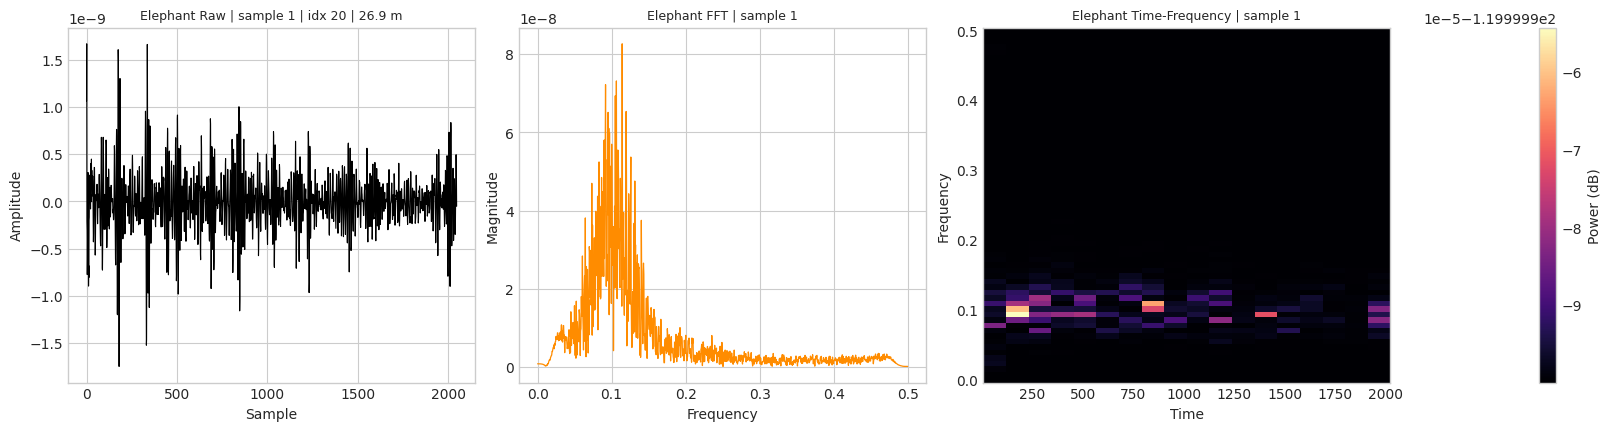

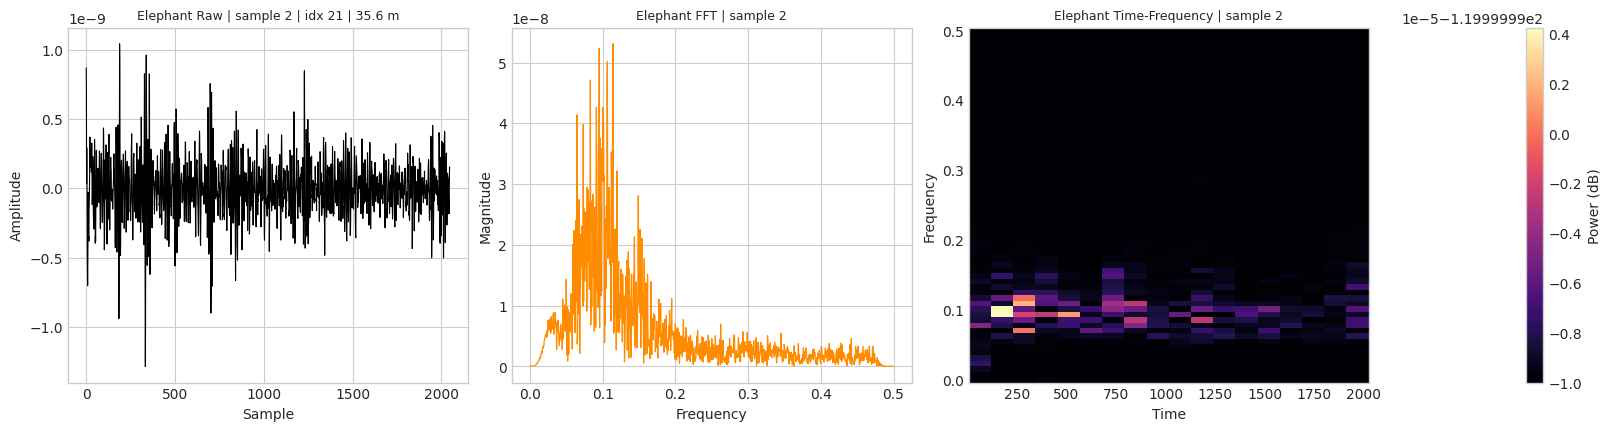

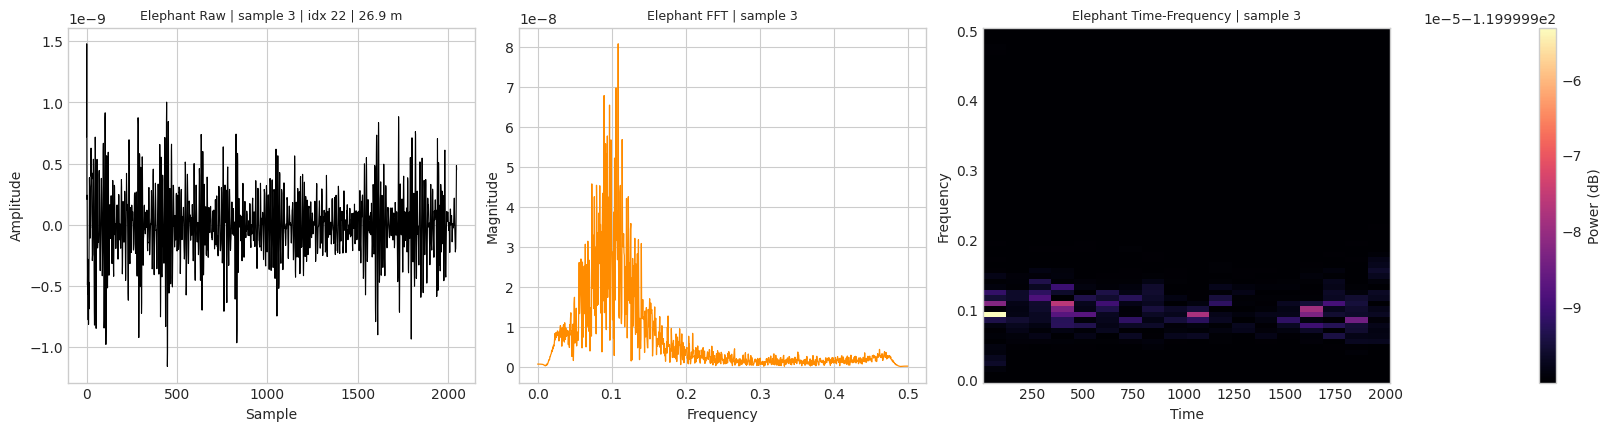

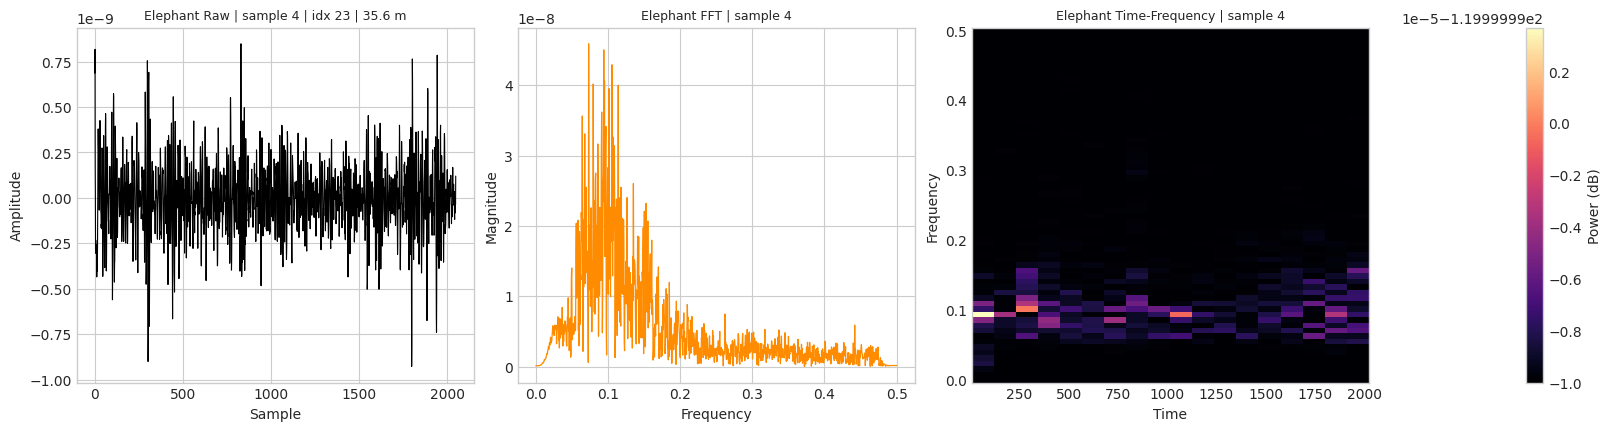

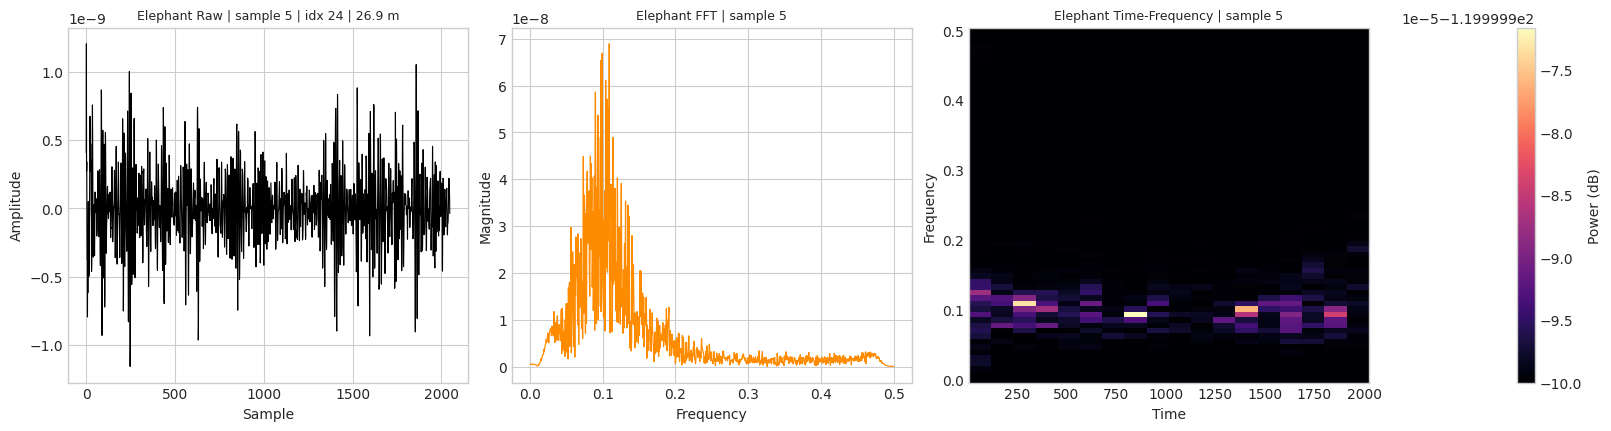

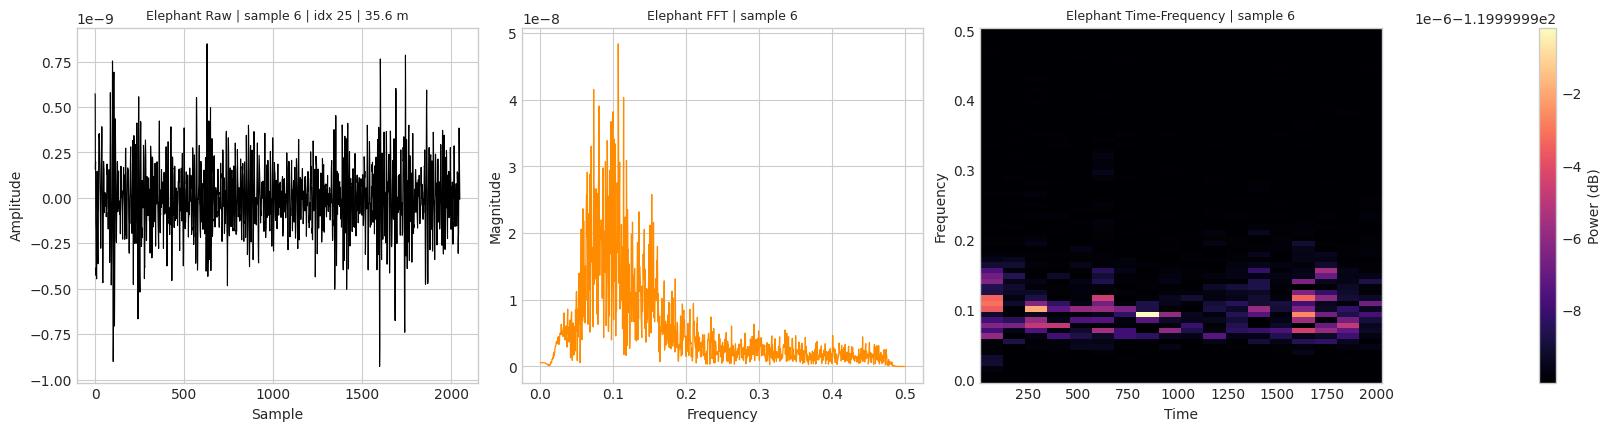

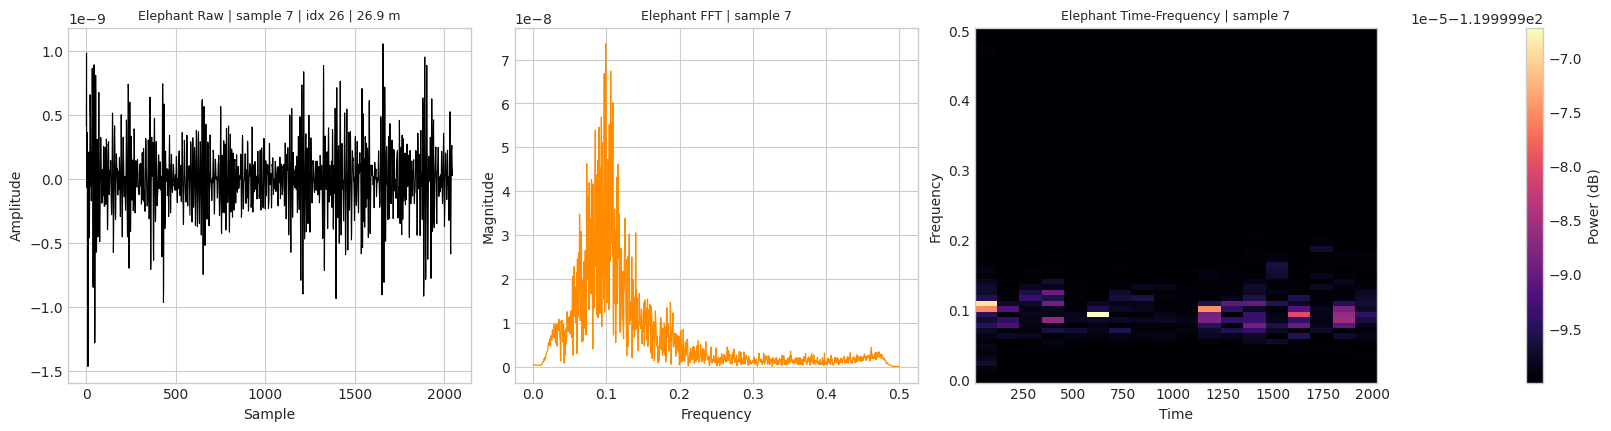

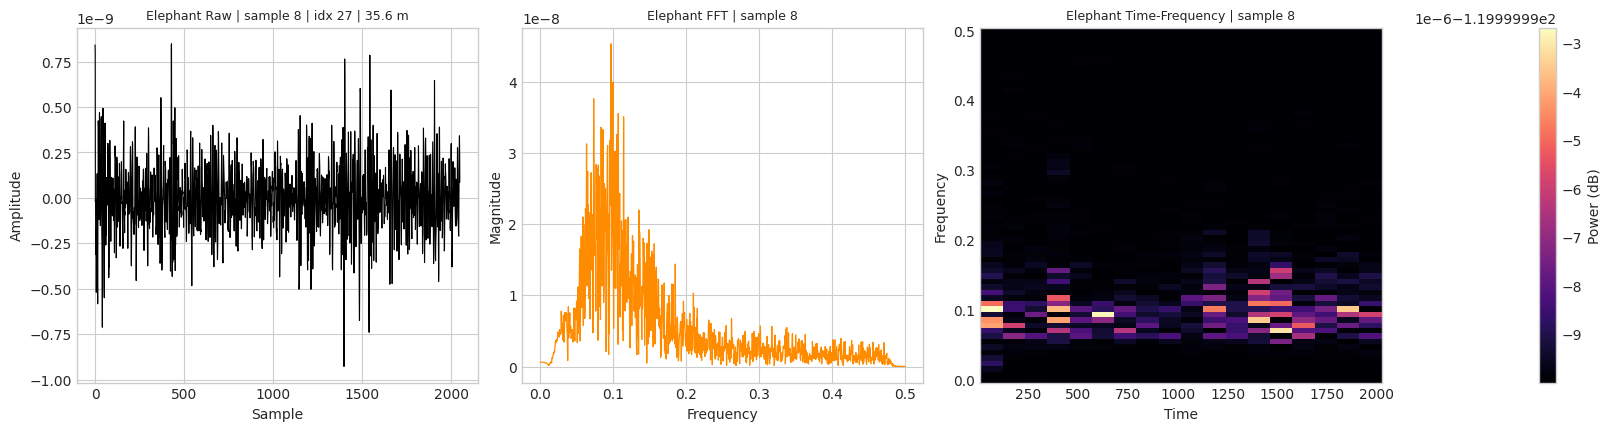

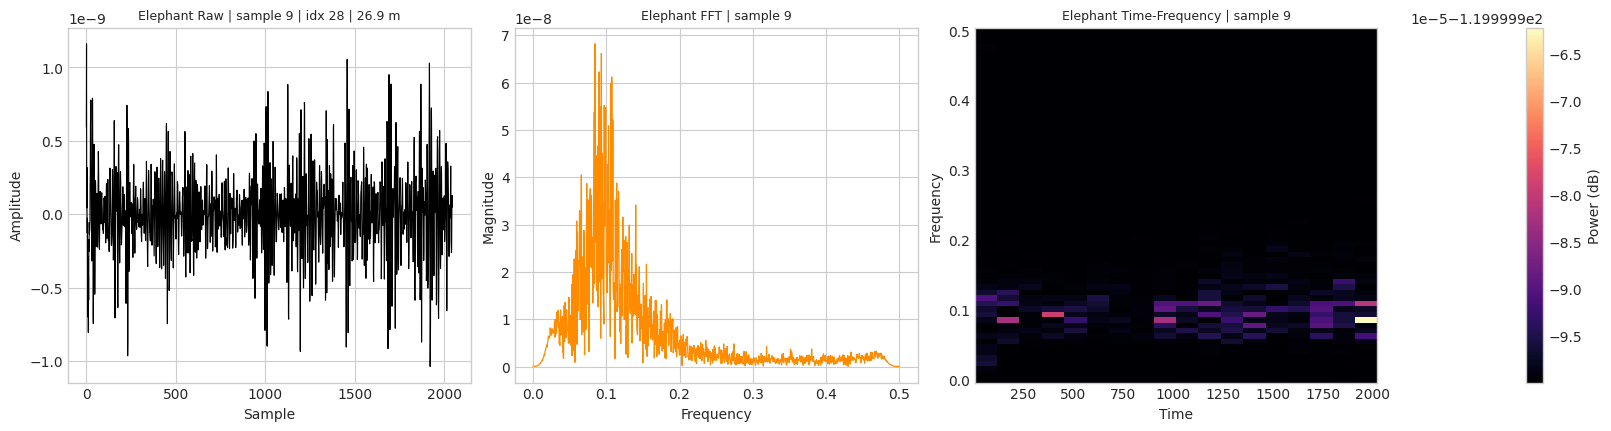

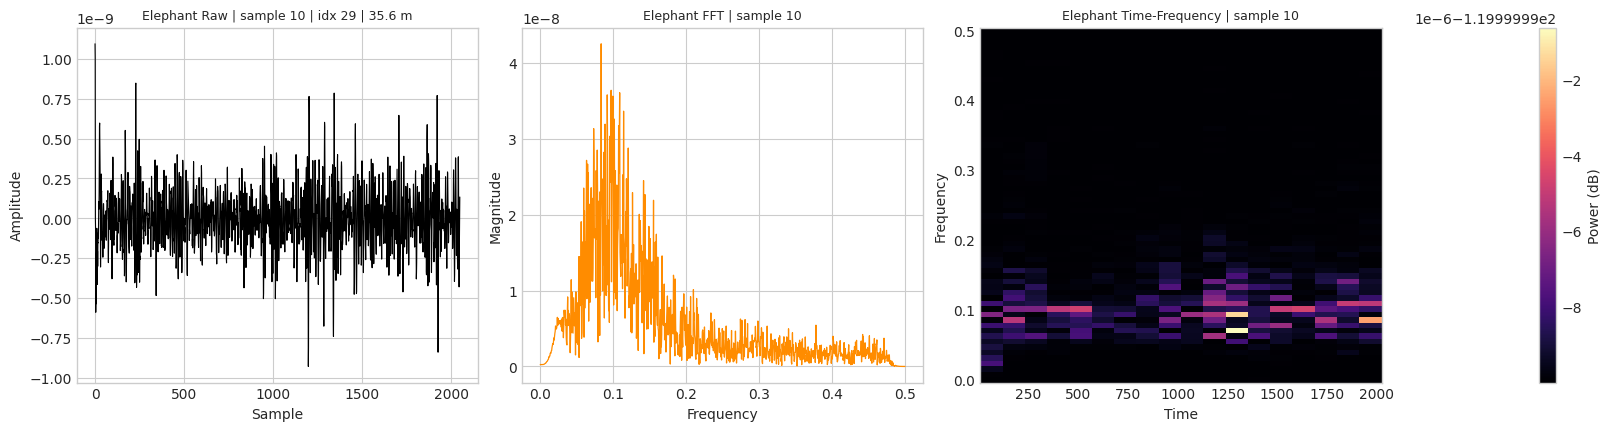

In [7]:
# Run Class A only (one by one)
samples_a = collect_samples_for_class(class_a, SAMPLES_PER_CLASS)
plot_class_one_by_one(class_a, samples_a)


Giraffe (class 6) -> 10 samples


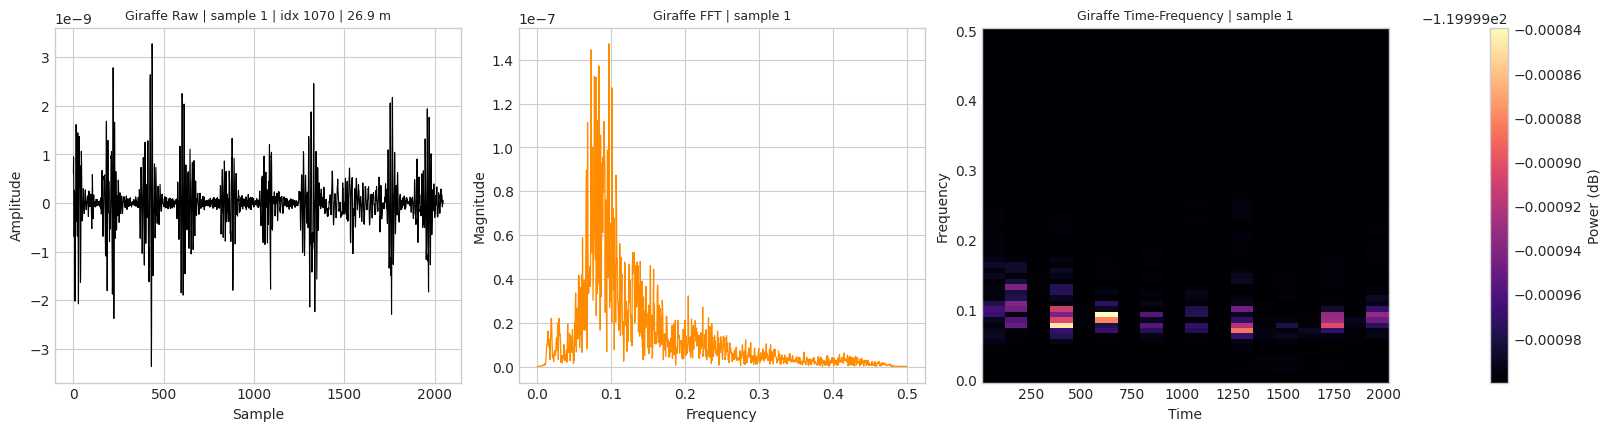

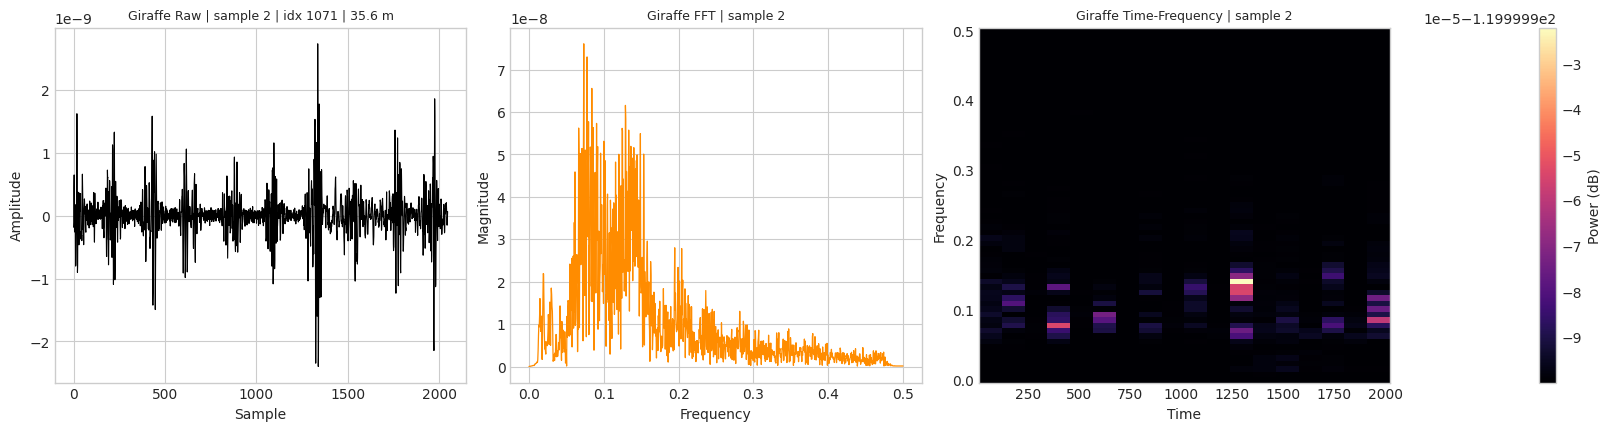

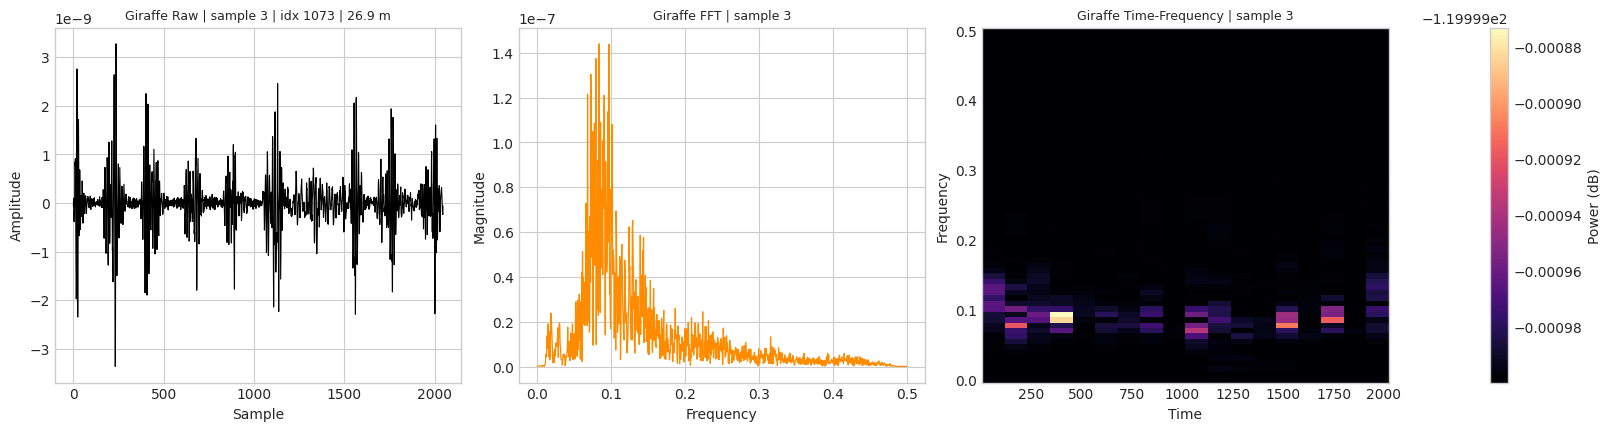

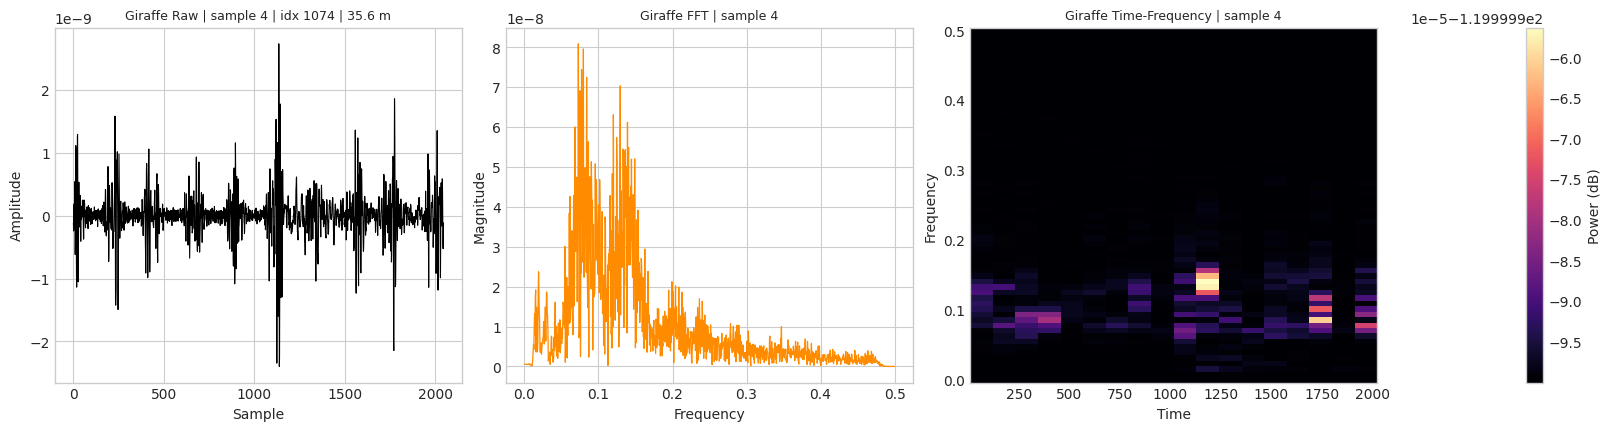

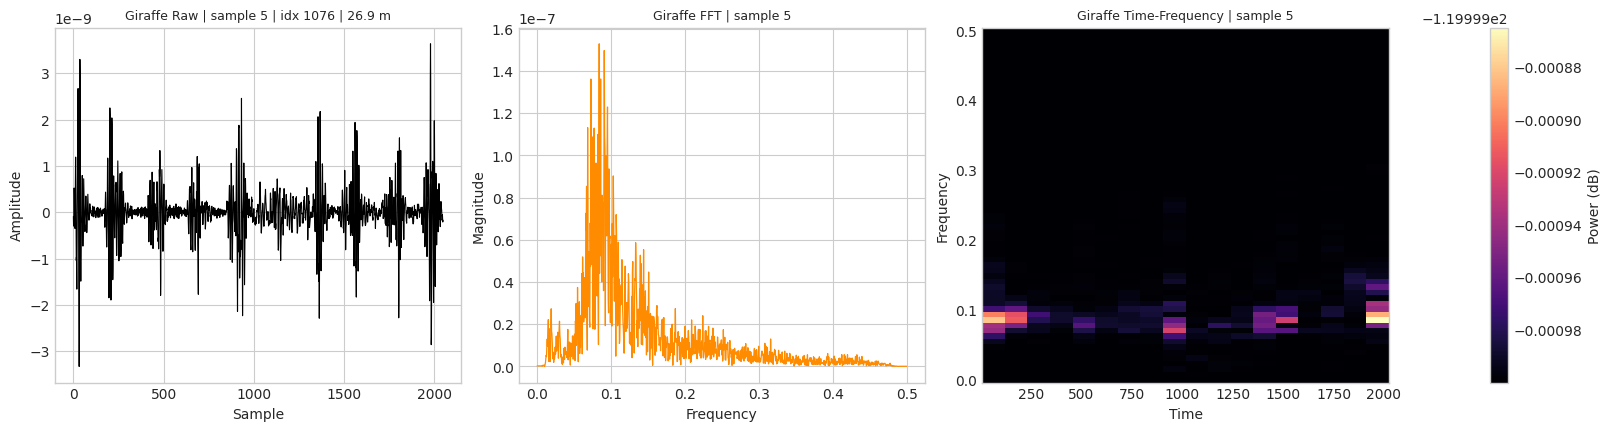

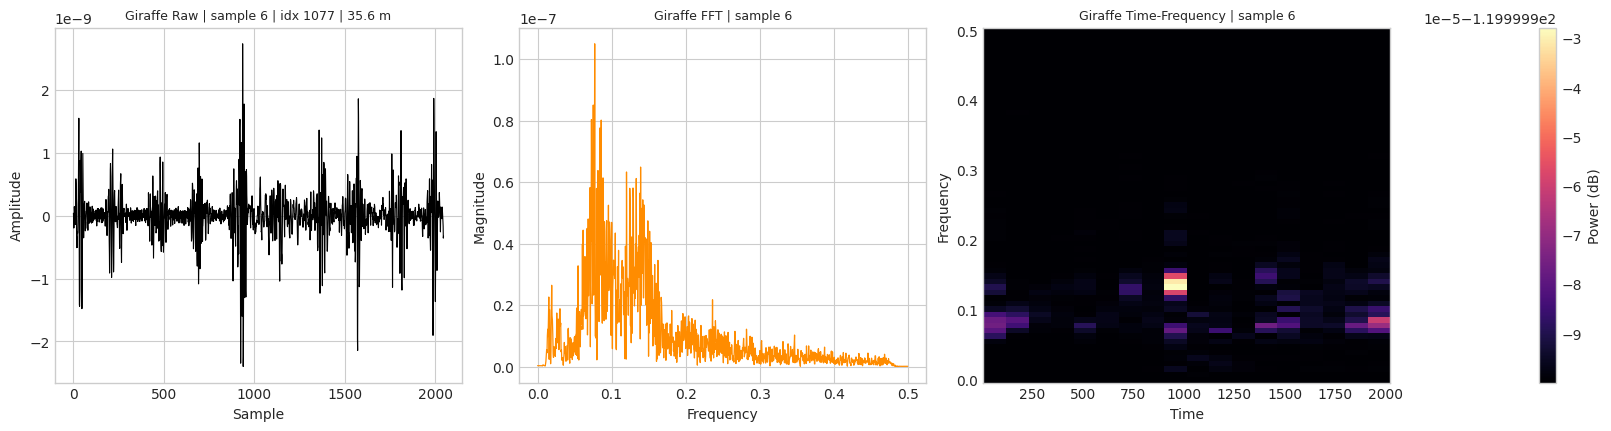

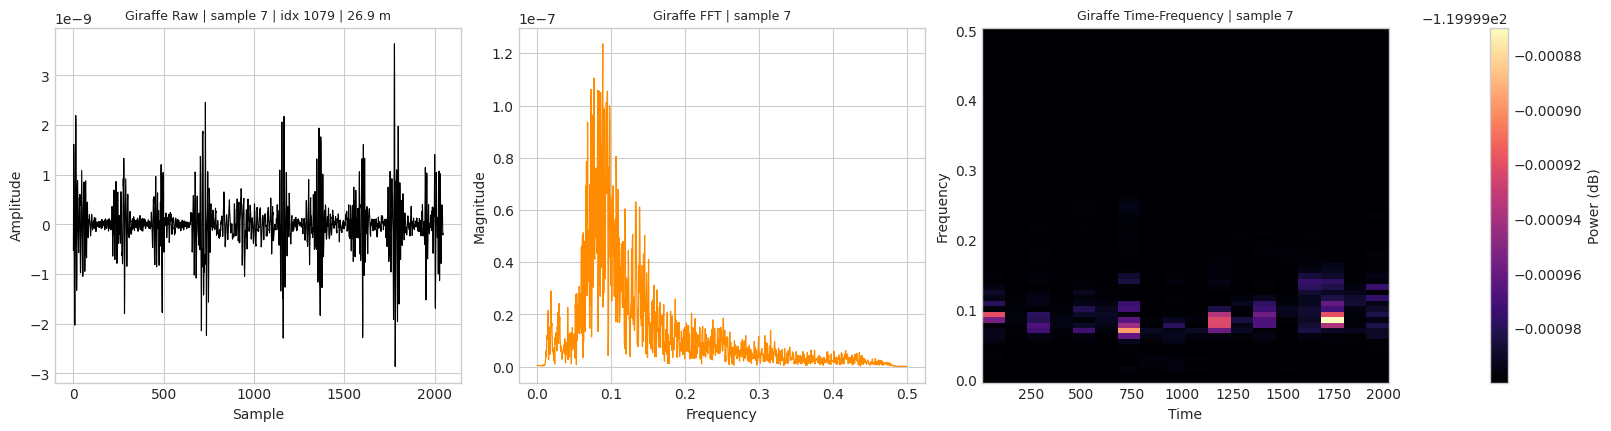

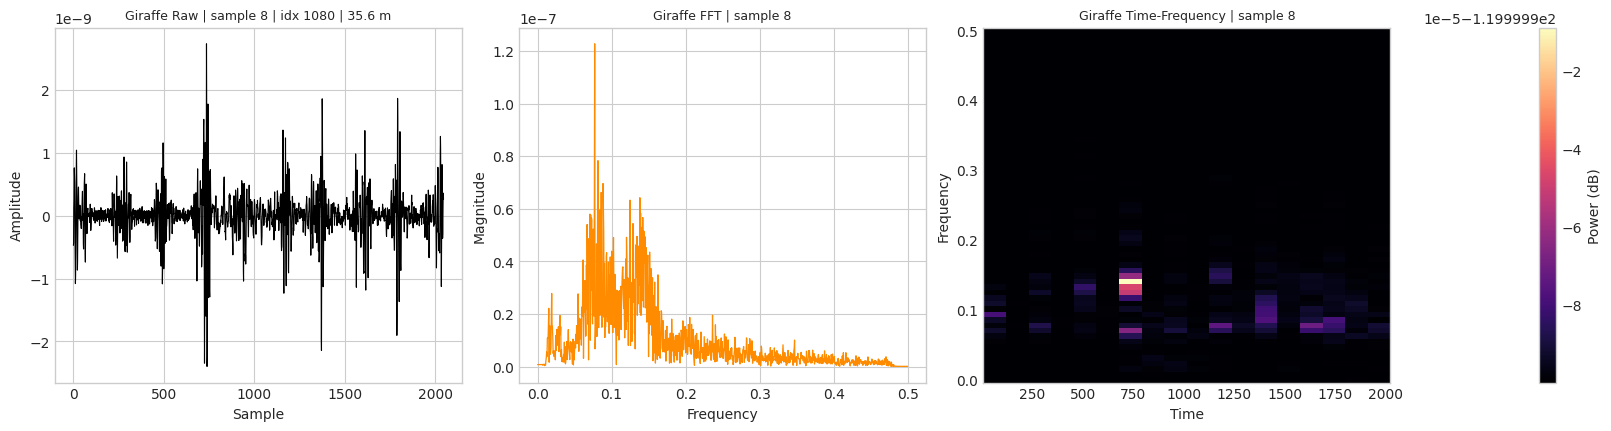

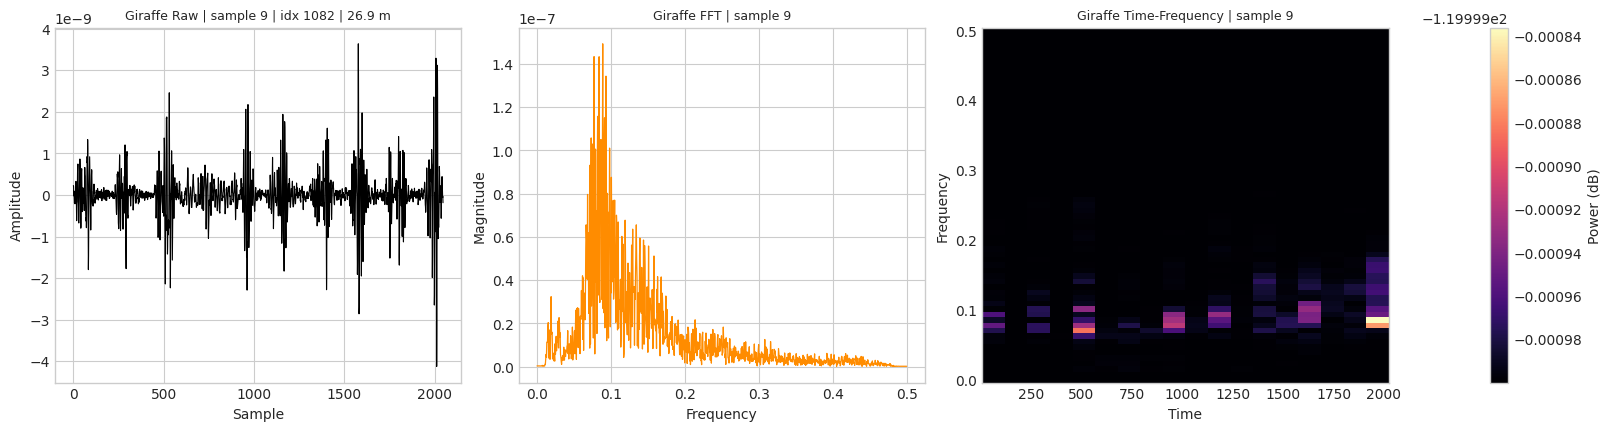

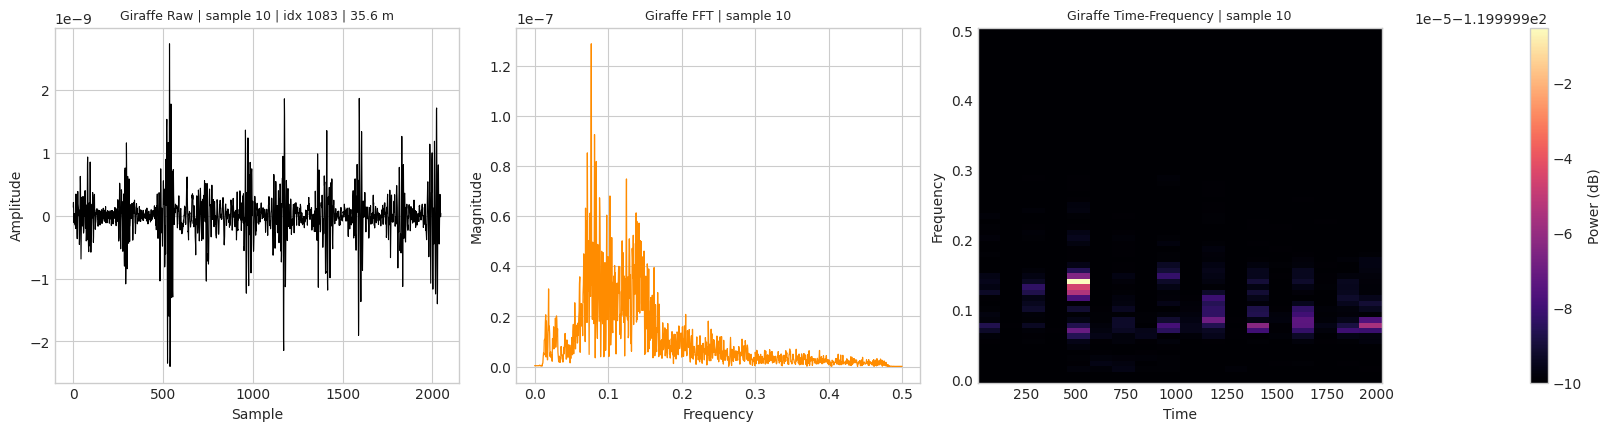

In [8]:
# Run Class B only (one by one)
samples_b = collect_samples_for_class(class_b, SAMPLES_PER_CLASS)
plot_class_one_by_one(class_b, samples_b)


Elephant (class 0) -> 10 samples


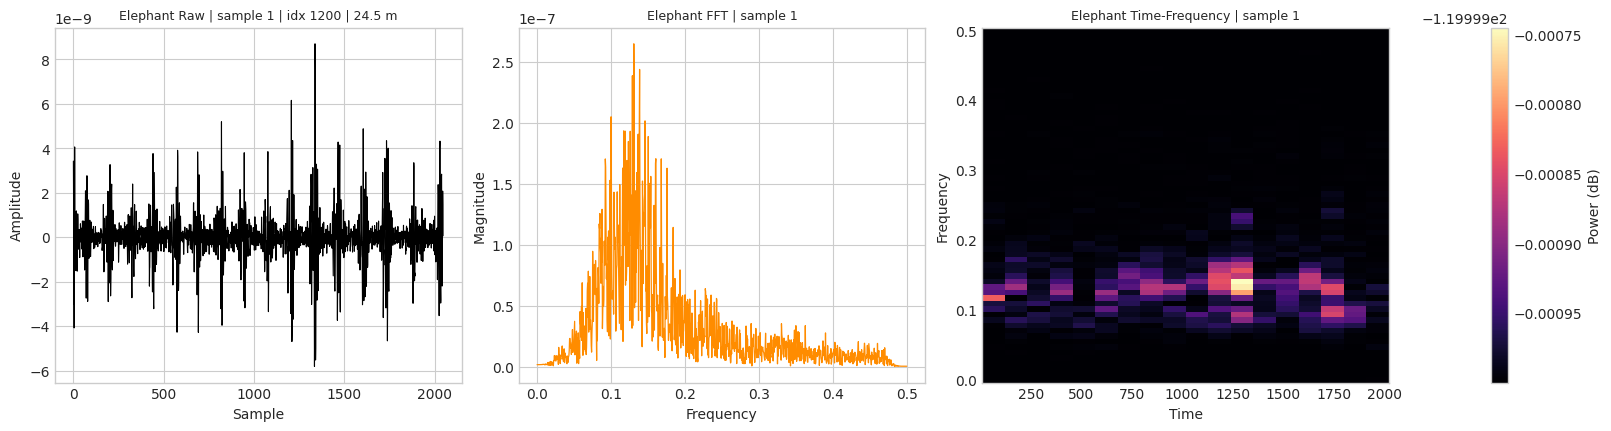

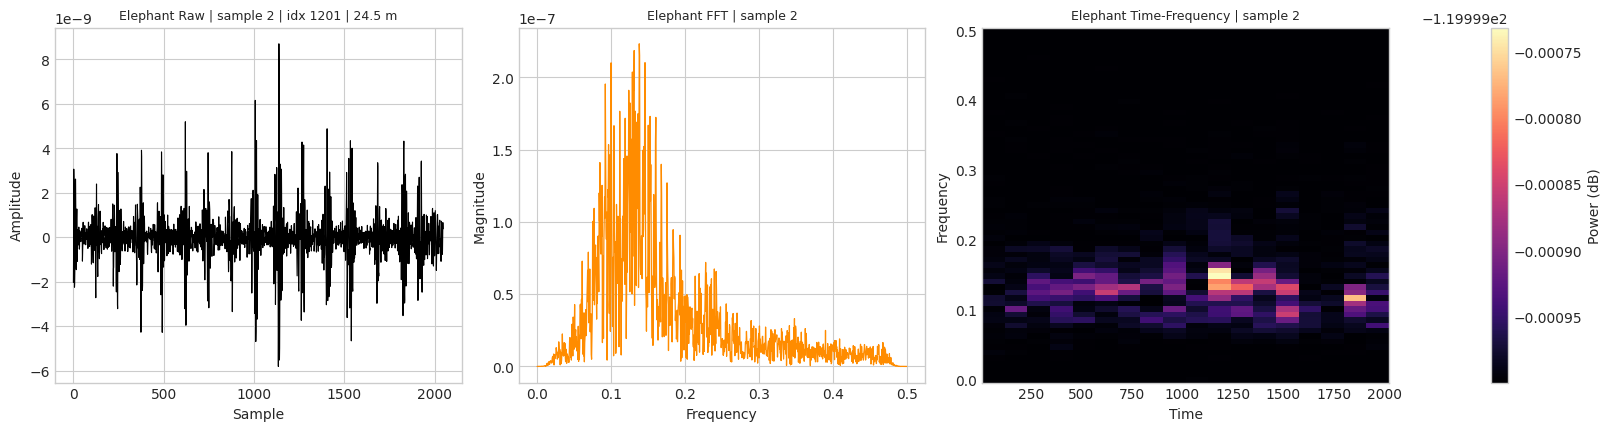

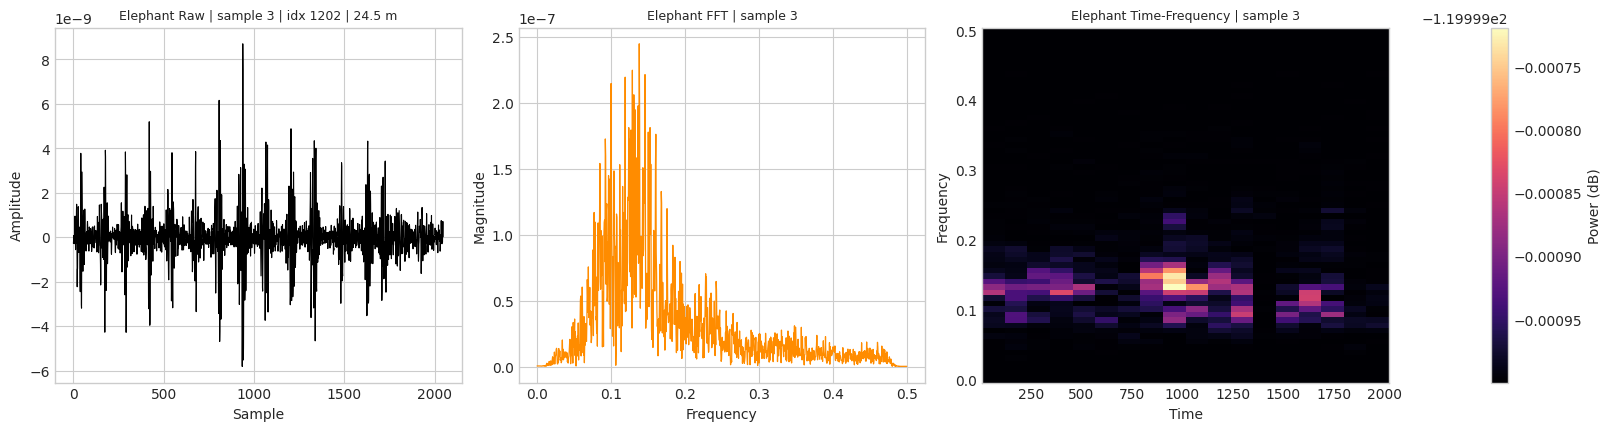

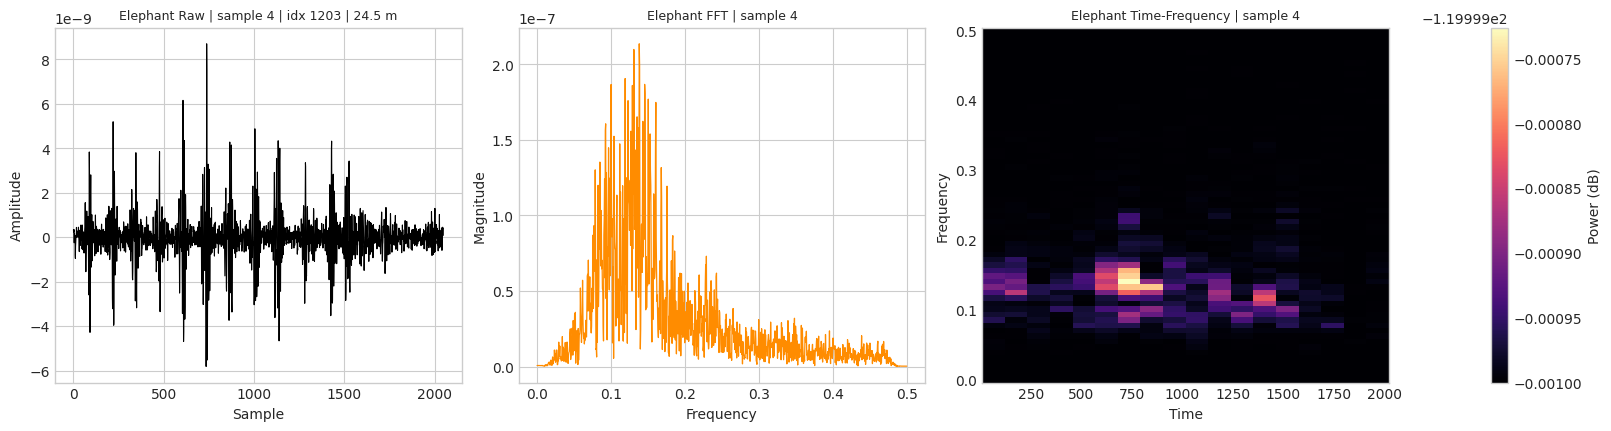

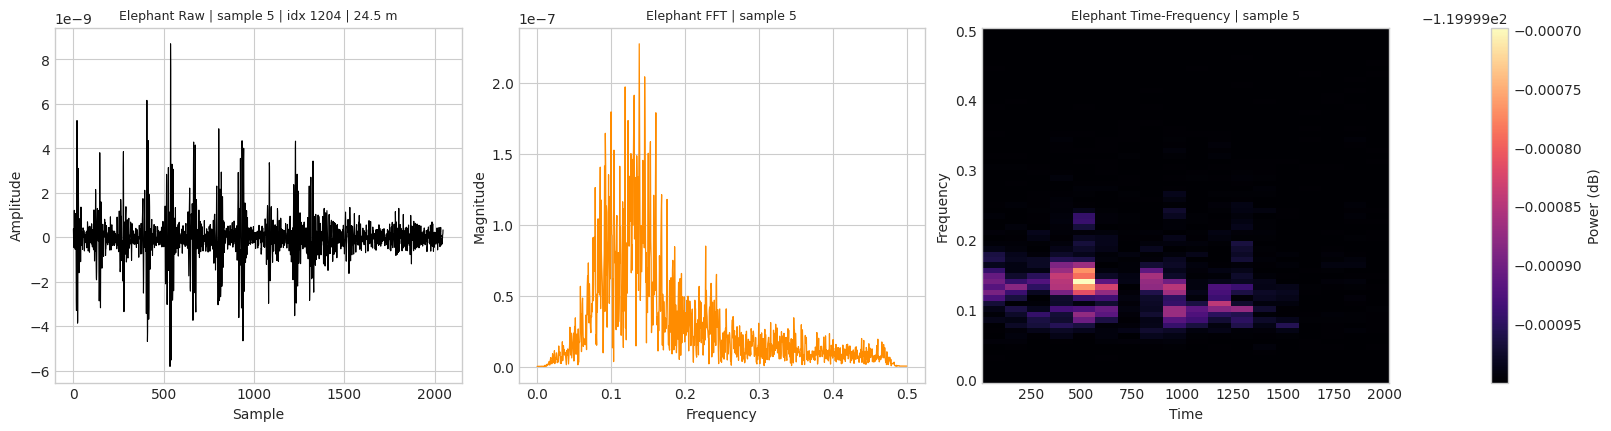

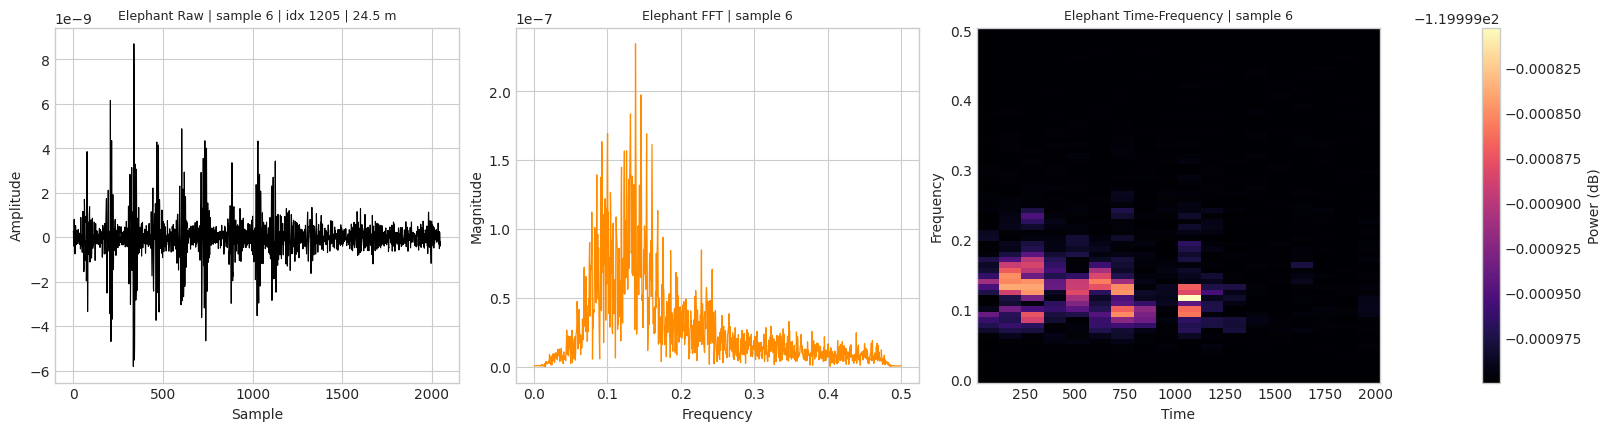

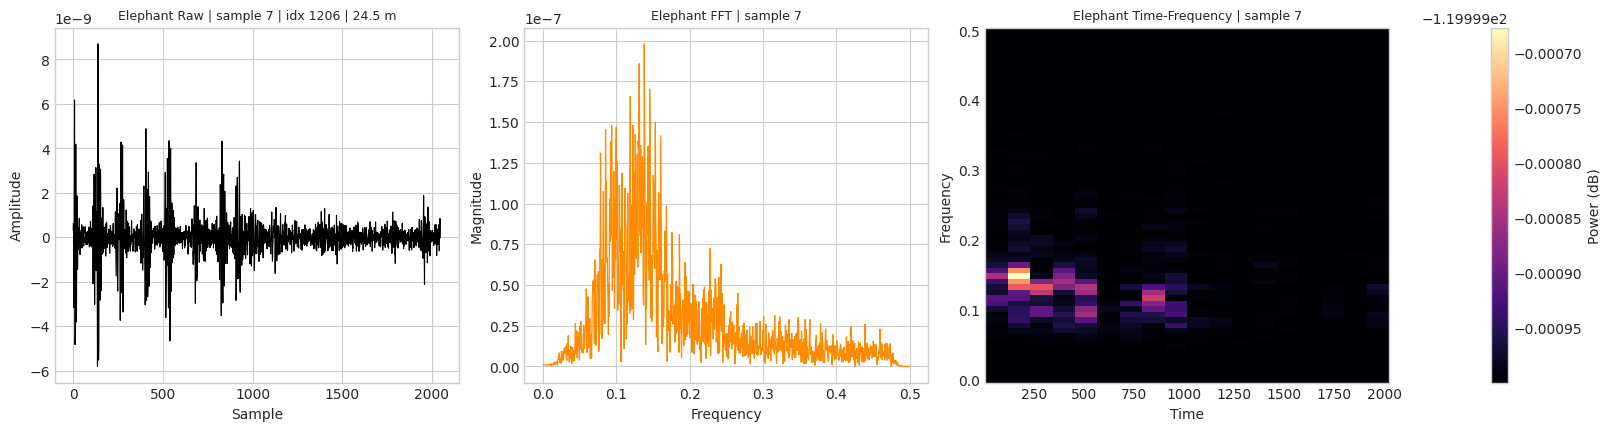

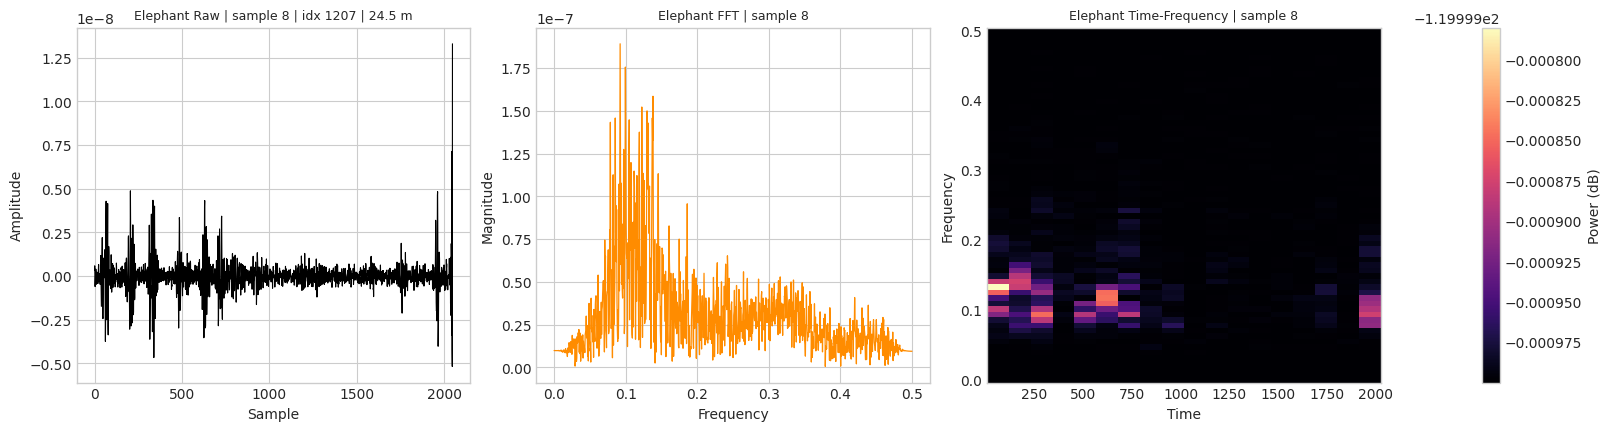

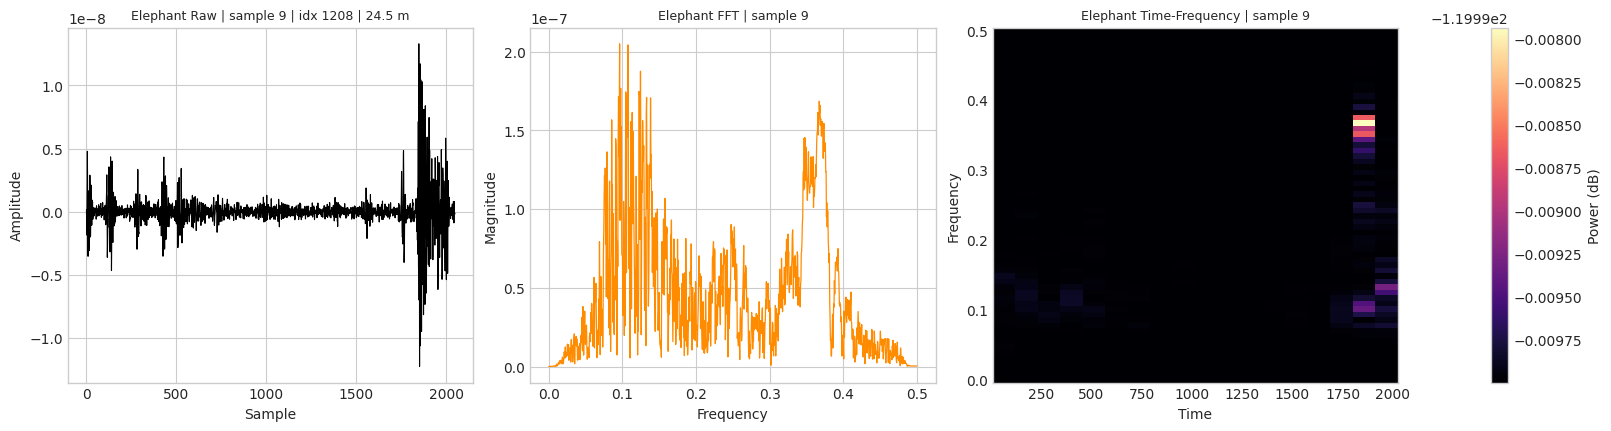

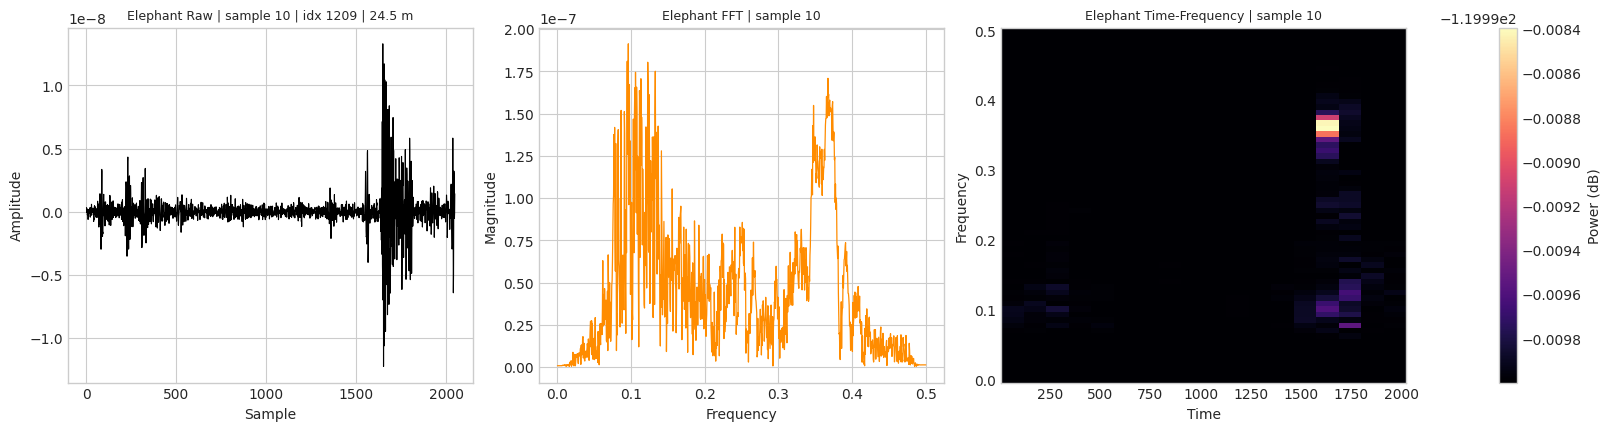

In [9]:
# Run Class A only (one by one)
samples_a = collect_samples_for_class(class_a, SAMPLES_PER_CLASS)
plot_class_one_by_one(class_a, samples_a)


Giraffe (class 5) -> 10 samples


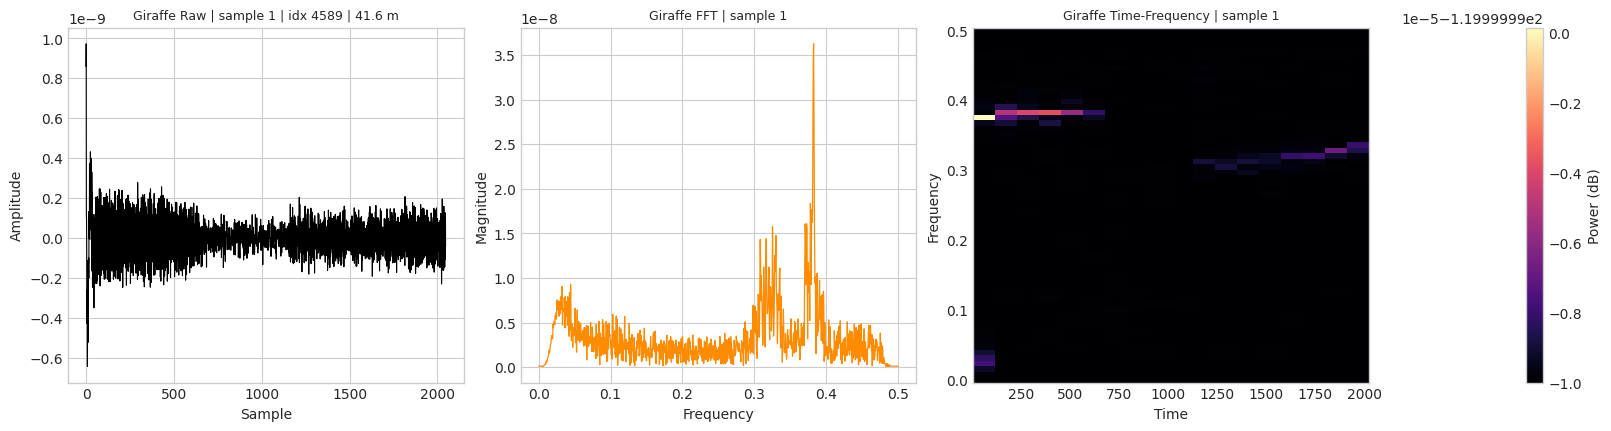

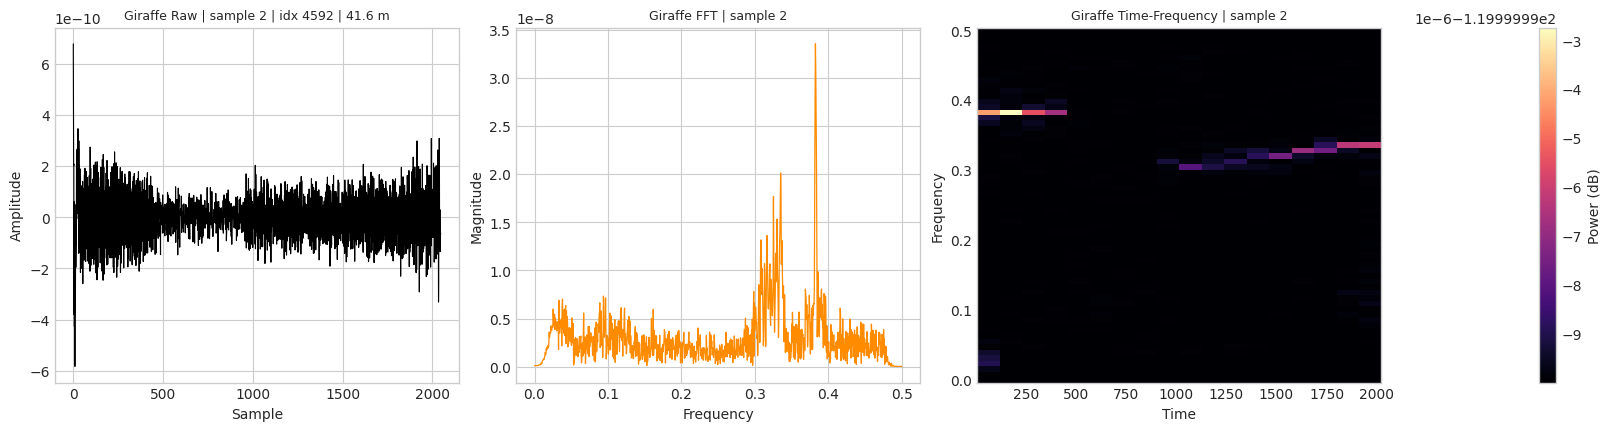

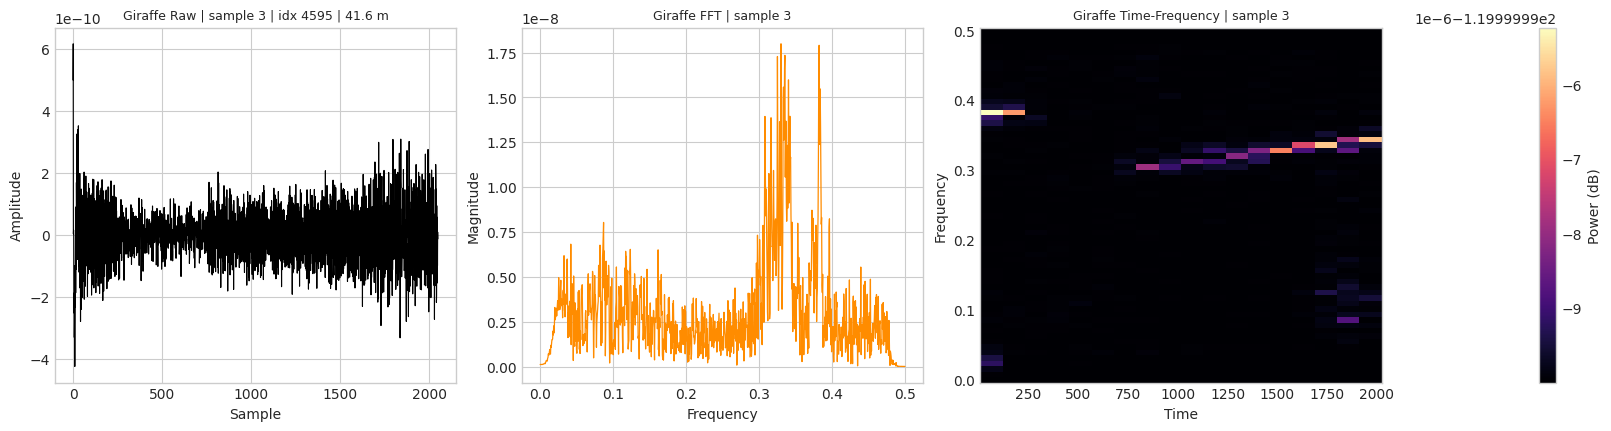

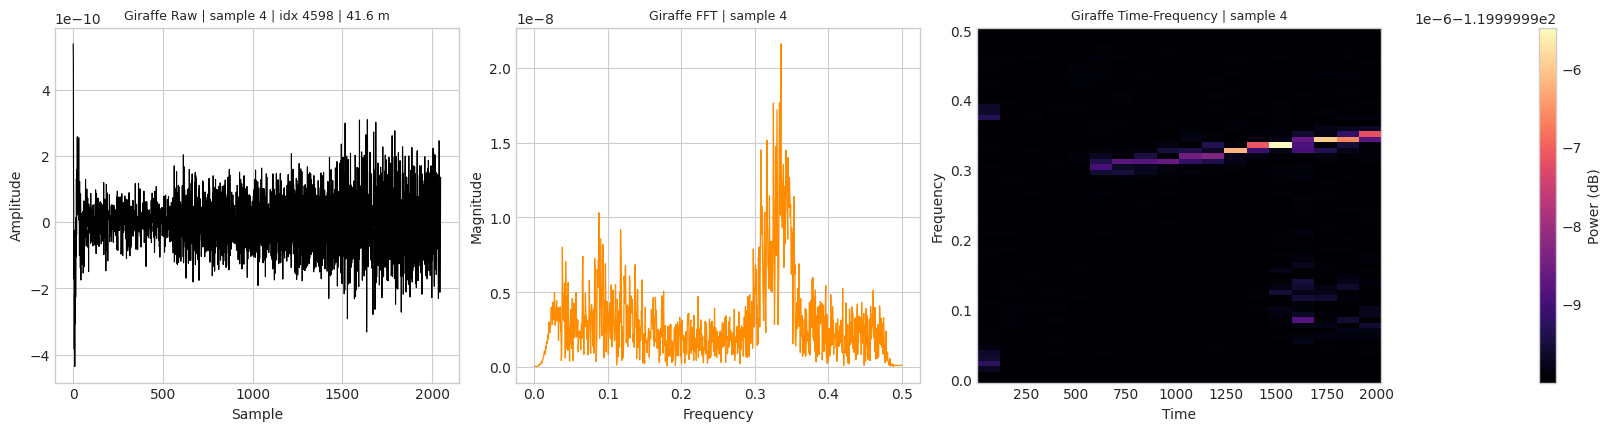

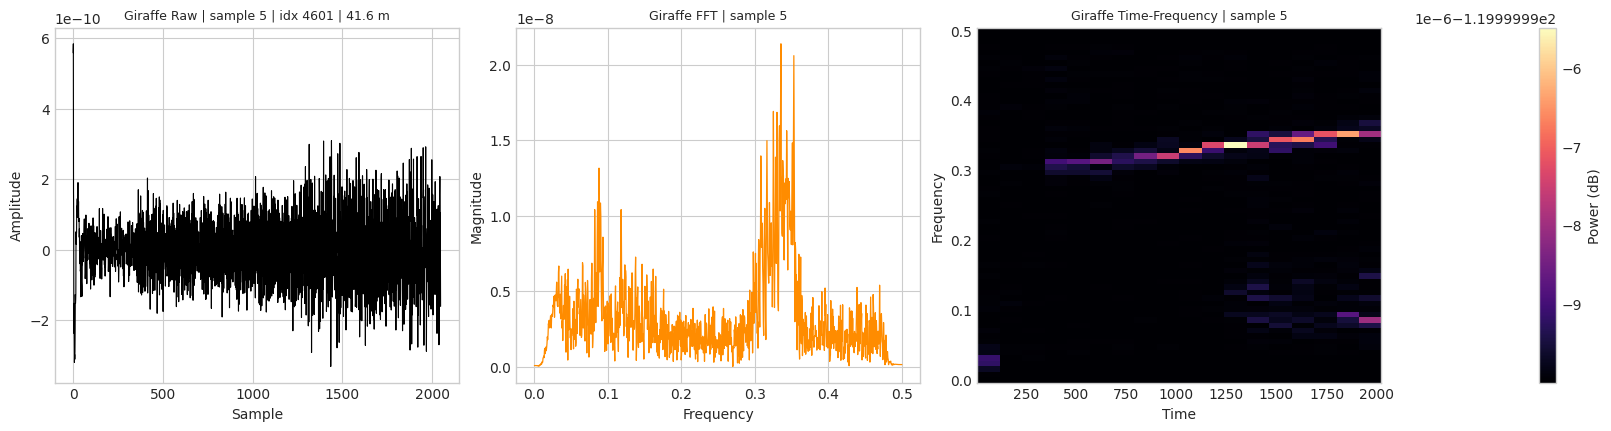

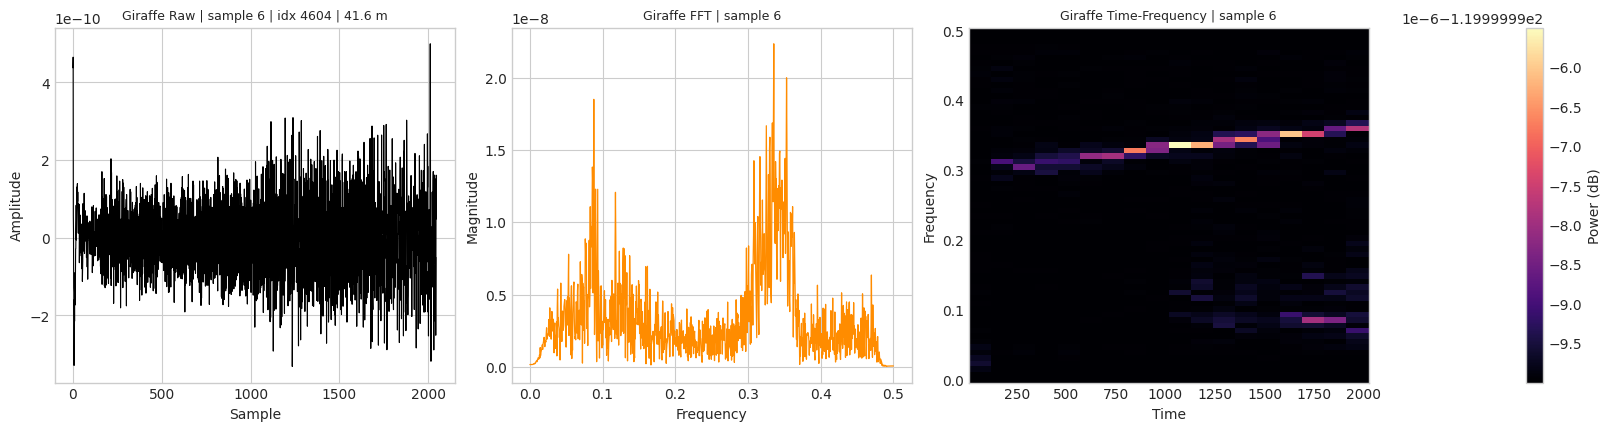

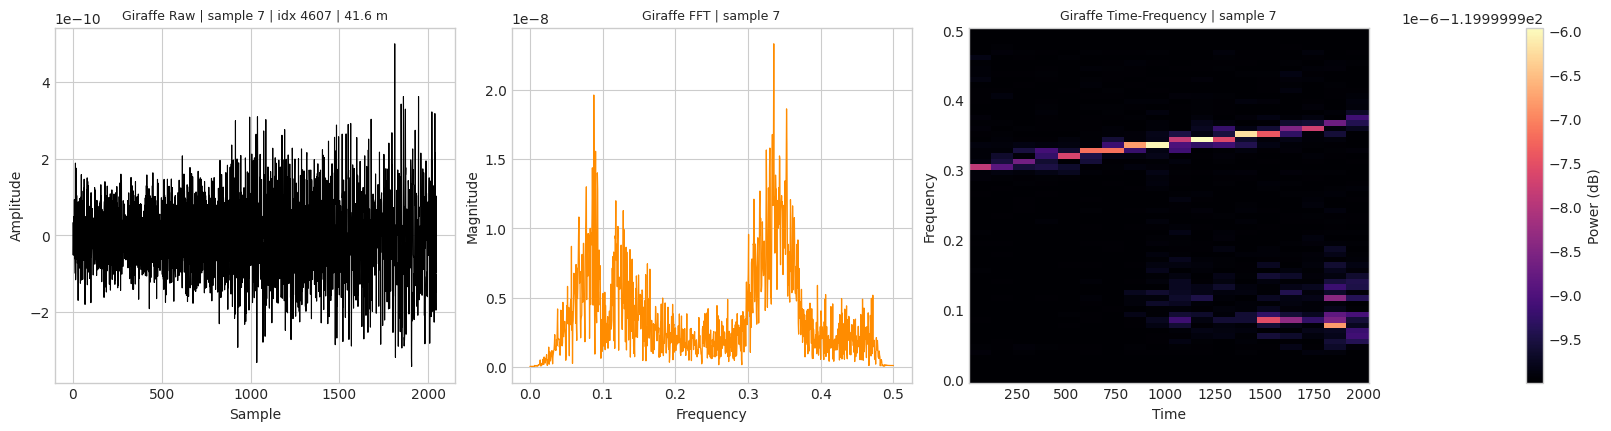

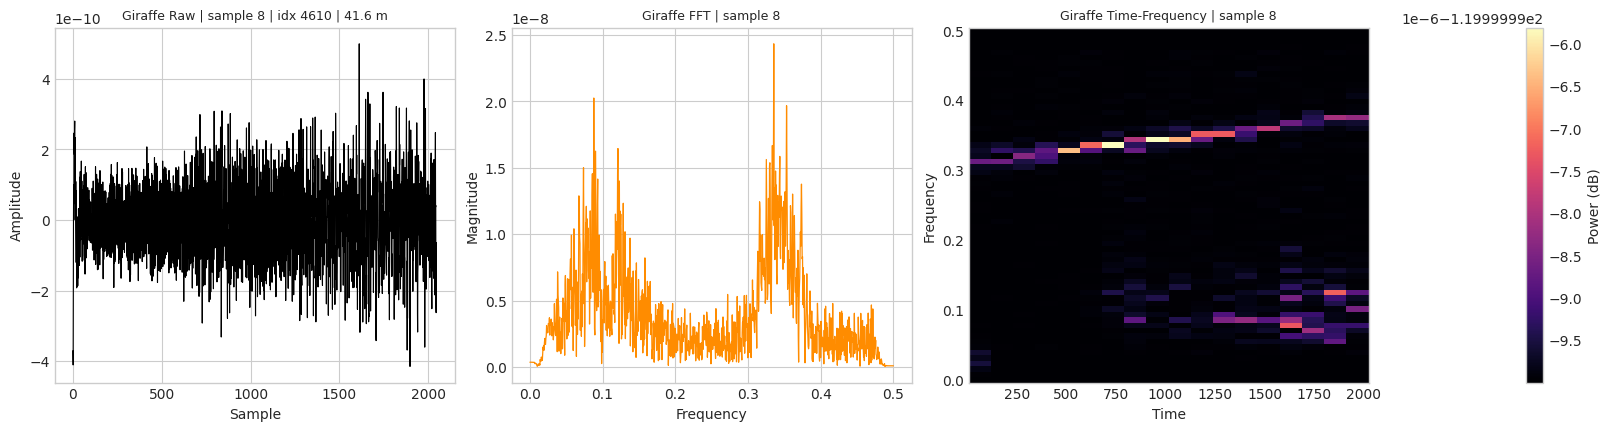

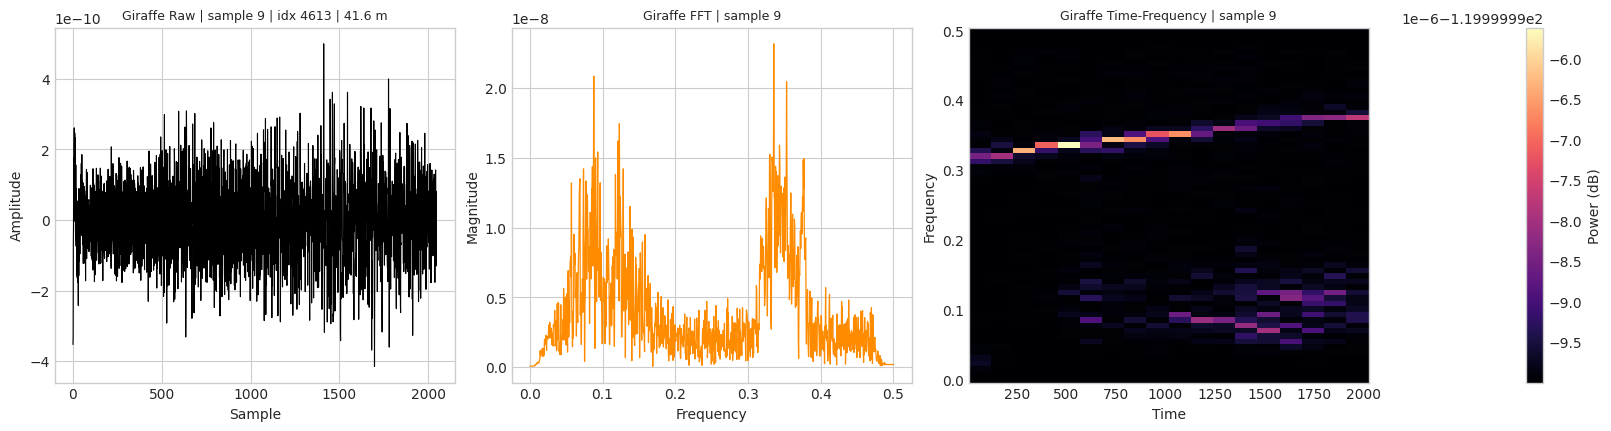

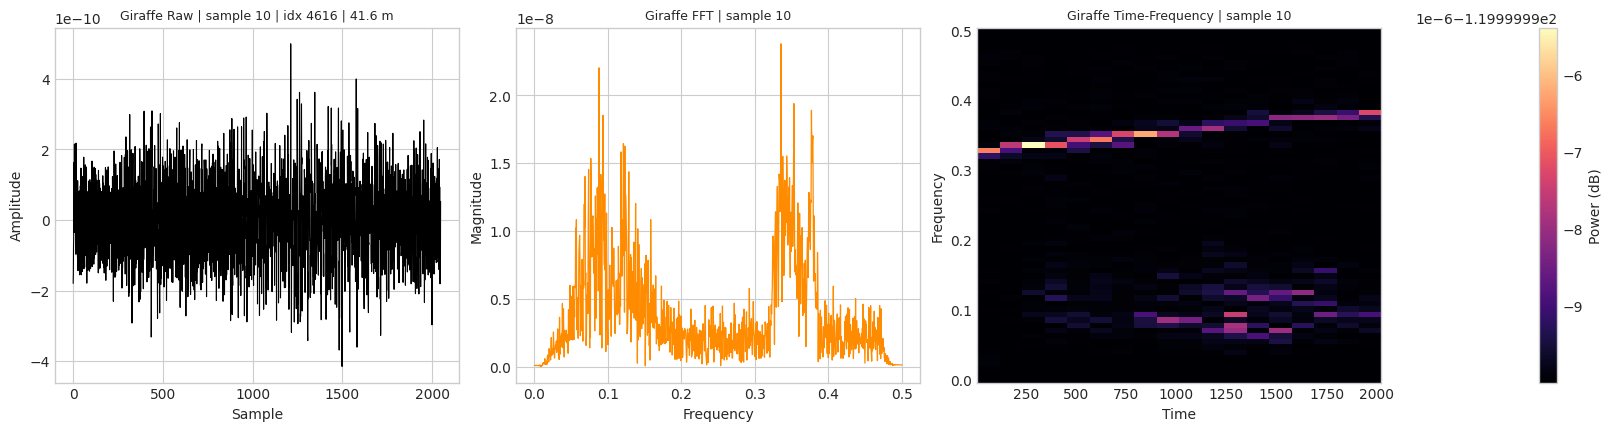

In [11]:
# Run Class A only (one by one)
samples_b = collect_samples_for_class(class_b, SAMPLES_PER_CLASS)
plot_class_one_by_one(class_b, samples_b)

In [9]:
# Step 1: Build Visibility Graph from Time Series
# A visibility graph converts a 1D signal into a graph by connecting "visible" points.
# Two points are connected if no other point is higher between them (on the line connecting them).

def build_visibility_graph(signal_data):
    """
    Build a visibility graph from a 1D time series.
    Returns adjacency matrix (N x N) where N = signal length.
    """
    n = len(signal_data)
    adj_matrix = np.zeros((n, n), dtype=int)
    
    for i in range(n):
        for j in range(i + 1, n):
            # Check if points i and j are visible
            is_visible = True
            for k in range(i + 1, j):
                # Check if point k blocks the line of sight between i and j
                # Using linear interpolation to check visibility
                y_line = signal_data[i] + (signal_data[j] - signal_data[i]) * (k - i) / (j - i)
                if signal_data[k] > y_line:
                    is_visible = False
                    break
            
            if is_visible:
                adj_matrix[i, j] = 1
                adj_matrix[j, i] = 1  # Symmetric matrix
    
    return adj_matrix


def get_graph_features(adj_matrix):
    """
    Extract simple features from adjacency matrix.
    Features:
    - Number of edges
    - Average degree
    - Density
    - Clustering coefficient (simplified)
    """
    n = adj_matrix.shape[0]
    num_edges = np.sum(adj_matrix) / 2  # Divide by 2 since matrix is symmetric
    degrees = np.sum(adj_matrix, axis=1)
    avg_degree = np.mean(degrees)
    density = 2 * num_edges / (n * (n - 1)) if n > 1 else 0
    
    return {
        'num_edges': num_edges,
        'avg_degree': avg_degree,
        'density': density,
        'max_degree': np.max(degrees),
        'min_degree': np.min(degrees),
    }


# Collect all visibility graphs for both classes
print("Building visibility graphs for all samples...")
vg_data = {}

for class_id in [class_a, class_b]:
    class_name = SPECIES_MAP.get(class_id, f"Class {class_id}")
    samples = collect_samples_for_class(class_id, SAMPLES_PER_CLASS)
    vg_data[class_id] = []
    
    print(f"\n{class_name} (class {class_id}):")
    
    for i, sample in enumerate(samples, start=1):
        raw_sig = sample['raw_signal']
        
        # Normalize signal to [0, 1] for visibility graph (improves numerical stability)
        raw_sig_norm = (raw_sig - np.min(raw_sig)) / (np.max(raw_sig) - np.min(raw_sig) + 1e-10)
        
        # Build visibility graph
        adj_matrix = build_visibility_graph(raw_sig_norm)
        features = get_graph_features(adj_matrix)
        
        vg_data[class_id].append({
            'trace_index': sample['trace_index'],
            'distance_m': sample['distance_m'],
            'adj_matrix': adj_matrix,
            'features': features,
        })
        
        print(f"  Sample {i}: edges={features['num_edges']:.0f}, avg_degree={features['avg_degree']:.2f}, density={features['density']:.4f}")

print("\nVisibility graphs built successfully!")

Building visibility graphs for all samples...

Elephant (class 1):
  Sample 1: edges=9962, avg_degree=9.73, density=0.0048
  Sample 2: edges=9160, avg_degree=8.95, density=0.0044
  Sample 3: edges=9890, avg_degree=9.66, density=0.0047
  Sample 4: edges=9028, avg_degree=8.82, density=0.0043
  Sample 5: edges=9907, avg_degree=9.67, density=0.0047
  Sample 6: edges=8925, avg_degree=8.72, density=0.0043
  Sample 7: edges=9910, avg_degree=9.68, density=0.0047
  Sample 8: edges=8911, avg_degree=8.70, density=0.0043
  Sample 9: edges=9932, avg_degree=9.70, density=0.0047
  Sample 10: edges=9046, avg_degree=8.83, density=0.0043

Giraffe (class 6):
  Sample 1: edges=11547, avg_degree=11.28, density=0.0055
  Sample 2: edges=9574, avg_degree=9.35, density=0.0046
  Sample 3: edges=11557, avg_degree=11.29, density=0.0055
  Sample 4: edges=9668, avg_degree=9.44, density=0.0046
  Sample 5: edges=11374, avg_degree=11.11, density=0.0054
  Sample 6: edges=9826, avg_degree=9.60, density=0.0047
  Sample 7

## 7. Lightweight Model Pipeline: Visibility Graph → Graph Embedding → Classification

Build a graph-based representation of signals (computationally efficient alternative to deep learning).

**Pipeline Steps:**
1. **Visibility Graph**: Convert time-series signal → graph structure
2. **Graph Embedding**: Compress graph → fixed-size vector
3. **Classification**: Simple classifier on embeddings